# 01 · Can a song have a star sign?

We scraped it and measured it. **1,325 playlists, 169,010 rows, 87,907 unique tracks**,
all twelve signs, collected 2026-10-11.

The answer is *barely*. Zodiac sign is predictable from a song at roughly **1.3× the
1-in-12 chance rate** — a real effect, confirmed against a control, and far too small
to build a product claim on.

This notebook reports that number, shows the control that makes it believable, and
then does something less comfortable: it walks back a conclusion an earlier version of
this same notebook reached. That earlier version argued the design was dangerous
because duplicate tracks leak across a random train/test split and inflate accuracy
enormously. On synthetic data that is true and dramatic. On the real scrape it almost
doesn't happen, and §3 shows why.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from lovify_ml import schema as S, data, synthetic as syn, zodiac as Z, viz

pd.set_option("display.width", 170, "display.max_columns", 40)

zodiac = pd.read_csv("../data/raw/zodiac.csv")
print(f"{len(zodiac):,} rows  ·  {zodiac[S.TRACK_ID].nunique():,} unique tracks  ·  "
      f"{zodiac.playlist_id.nunique():,} playlists  ·  {zodiac[S.STAR_SIGN].nunique()} signs")
print(f"chance accuracy = 1/12 = {S.CHANCE_ACCURACY:.4f}")

169,010 rows  ·  87,907 unique tracks  ·  1,325 playlists  ·  12 signs
chance accuracy = 1/12 = 0.0833


## 1 · Getting features at all

The scrape carries genre, popularity and release year straight from the API. It cannot
carry audio features, because `/v1/audio-features` was deprecated on 2024-11-27 and
returns 403 for this app. Those have to be looked up in a local store assembled from
pre-deprecation dumps.

The join rate is not housekeeping. It decides how much of the original design is still
possible at all.

In [2]:
store = pd.read_csv("../data/raw/feature_store.csv", low_memory=False)

# The scrape already has duration_ms; joining it again would produce _x/_y columns.
add = [f for f in S.AUDIO_FEATURES if f in store.columns and f not in zodiac.columns]
zf = zodiac.merge(store[[S.TRACK_ID] + add].drop_duplicates(S.TRACK_ID),
                  on=S.TRACK_ID, how="left")

FEATS = [f for f in S.AUDIO_FEATURES if f in zf.columns]
resolved = zf[zf[add[0]].notna()]
missing = zf[zf[add[0]].isna()]

print(f"feature store      : {len(store):,} tracks")
print(f"scraped tracks     : {zodiac[S.TRACK_ID].nunique():,}")
print(f"resolved           : {resolved[S.TRACK_ID].nunique():,}  "
      f"({resolved[S.TRACK_ID].nunique()/zodiac[S.TRACK_ID].nunique():.1%})")
print()
print("who falls in the gap:")
print(f"  resolved : median year {resolved[S.YEAR].median():.0f}, "
      f"median popularity {resolved[S.POPULARITY].median():.0f}")
print(f"  missing  : median year {missing[S.YEAR].median():.0f}, "
      f"median popularity {missing[S.POPULARITY].median():.0f}")

feature store      : 1,419,043 tracks
scraped tracks     : 87,907
resolved           : 36,116  (41.1%)

who falls in the gap:
  resolved : median year 2015, median popularity 67
  missing  : median year 2023, median popularity 51


**41% coverage, and the missing 59% is not a random sample.** Resolved tracks
have a median release year of 2015; unresolved ones 2023.

The reason is structural and permanent. Every dump of Spotify audio features was
captured before the endpoint closed, so nothing released since can ever appear in one.
Zodiac playlists are full of recent music. That gap will widen every year, and no
amount of extra data fixes it.

In [3]:
work = zf.dropna(subset=FEATS).copy()
print(f"analysis set: {len(work):,} rows, {work[S.TRACK_ID].nunique():,} tracks, "
      f"{len(FEATS)} audio features")

analysis set: 92,443 rows, 36,116 tracks, 10 audio features


## 2 · The control, first

Before any accuracy figure means anything, one question has to be answered: **would
this pipeline produce a number above chance even on labels that are pure noise?**

So we scraped a control — playlists with nothing to do with astrology (study, gym,
road trip, shower songs) — assigned them **random zodiac labels**, and ran the
identical pipeline. If the control scores what the real data scores, we measured our
own machinery and nothing else.

This is the single most important cell in the notebook.

In [4]:
import glob
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def grouped_score(df, num, cat=(), model="rf", n_splits=5):
    """Balanced accuracy, grouped by playlist cluster so correlated playlists
    cannot straddle the split. Balanced because the class sizes are uneven
    and uneven classes move the baseline -- see section 5."""
    from sklearn.ensemble import RandomForestClassifier

    d = df.dropna(subset=list(num) + list(cat))
    d = Z.deduplicate(d, "majority")
    X = d[list(num)].to_numpy(float)
    for c in cat:
        X = np.hstack([X, pd.factorize(d[c])[0].reshape(-1, 1)])
    y = d[S.STAR_SIGN].to_numpy()
    g = (d[S.PLAYLIST_CLUSTER].to_numpy() if S.PLAYLIST_CLUSTER in d.columns
         else d[S.TRACK_ID].to_numpy())
    k = min(n_splits, len(np.unique(g)))
    scores = []
    for tr, te in GroupKFold(n_splits=k).split(X, y, g):
        m = (RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=0)
             if model == "rf" else
             make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)))
        m.fit(X[tr], y[tr])
        scores.append(balanced_accuracy_score(y[te], m.predict(X[te])))
    return float(np.mean(scores)), float(np.std(scores)), len(d)


control = pd.concat([pd.read_csv(f) for f in
                     glob.glob("../data/interim/zodiac_control_scrape/*.csv")],
                    ignore_index=True)
rng = np.random.default_rng(0)
control[S.STAR_SIGN] = rng.choice(S.ZODIAC_SIGNS, size=len(control))
cf = control.merge(store[[S.TRACK_ID] + add].drop_duplicates(S.TRACK_ID),
                   on=S.TRACK_ID, how="left")

c_mean, c_sd, c_n = grouped_score(cf, FEATS, model="lr")
# size-matched, so the comparison is not confounded by sample size
z_mean, z_sd, z_n = grouped_score(
    zf.sample(n=12_000, random_state=0), FEATS, model="lr")

print(f"control playlists: {control.playlist_id.nunique()}  (partial -- see note below)")
print()
print(f"  {'CONTROL, random labels':<30} {c_mean:.4f} ± {c_sd:.4f}   "
      f"{c_mean/S.CHANCE_ACCURACY:.2f}× chance   n={c_n:,}")
print(f"  {'zodiac, size-matched':<30} {z_mean:.4f} ± {z_sd:.4f}   "
      f"{z_mean/S.CHANCE_ACCURACY:.2f}× chance   n={z_n:,}")
print(f"\n  gap: {z_mean - c_mean:+.4f}   (pre-registered bar: +0.0200)")

control playlists: 71  (partial -- see note below)

  CONTROL, random labels         0.0785 ± 0.0055   0.94× chance   n=2,915
  zodiac, size-matched           0.1081 ± 0.0074   1.30× chance   n=5,256

  gap: +0.0296   (pre-registered bar: +0.0200)


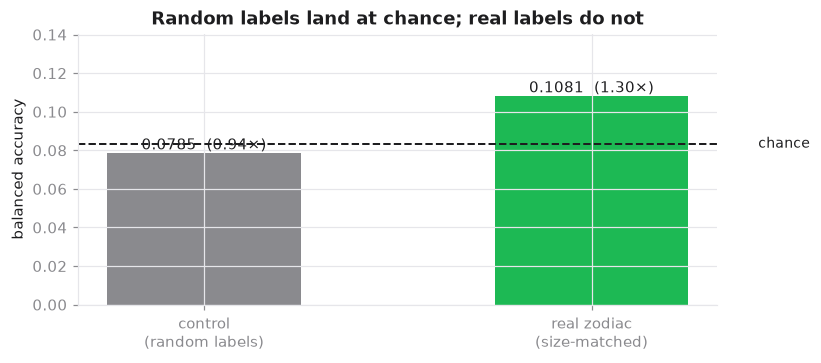

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 3.2))
bars = ["control\n(random labels)", "real zodiac\n(size-matched)"]
vals = [c_mean, z_mean]
ax.bar(bars, vals, color=[viz.MUTED, viz.ACCENT], width=.5)
ax.axhline(S.CHANCE_ACCURACY, color=viz.INK, ls="--", lw=1.3)
ax.text(1.42, S.CHANCE_ACCURACY, " chance", va="center", fontsize=9)
for i, v in enumerate(vals):
    ax.text(i, v + .002, f"{v:.4f}  ({v/S.CHANCE_ACCURACY:.2f}×)", ha="center", fontsize=10)
ax.set_ylabel("balanced accuracy"); ax.set_ylim(0, max(vals) * 1.3)
ax.set_title("Random labels land at chance; real labels do not")
plt.show()

**The control sits at chance (0.94×) and the real data does not (1.30×).**

That is the result that licenses everything else in this notebook. The pipeline is not
manufacturing a signal out of nothing — grouped splits, deduplication, balanced
accuracy and all, it correctly reports *nothing* when there is nothing. So the small
edge the real labels show is real.

**Caveat, stated plainly:** the control is 71 playlists, not the 480 planned. Spotify
rate-limited the app mid-collection — see §6. The gap clears the pre-registered bar,
but on a thin sample. Finishing the control is the highest-value open task.

## 3 · The trap we guarded against, which did not bite

The previous version of this notebook was built around a leakage mechanism:
scraped playlists copy each other, so the *same track with the same label* lands on
both sides of a random split, the model memorises it, and the reported accuracy is
recall of the training set wearing a disguise.

That mechanism is real, and on synthetic data built to contain it, it is enormous.

In [6]:
from sklearn.tree import DecisionTreeClassifier


def leak_probe(df, feats, label):
    """Split the test set by whether the model already saw that track."""
    tr, te = Z.naive_split(df, 0.25, seed=0)
    seen = te[S.TRACK_ID].isin(set(tr[S.TRACK_ID])).to_numpy()
    m = DecisionTreeClassifier(random_state=0).fit(
        tr[feats].to_numpy(float), tr[S.STAR_SIGN].to_numpy())
    a_seen = m.score(te[seen][feats].to_numpy(float), te[seen][S.STAR_SIGN].to_numpy())
    a_unseen = m.score(te[~seen][feats].to_numpy(float), te[~seen][S.STAR_SIGN].to_numpy())
    print(f"{label}")
    print(f"  track WAS in training (n={seen.sum():>6,}) : {a_seen:>6.1%}")
    print(f"  track was NOT         (n={(~seen).sum():>6,}) : {a_unseen:>6.1%}")
    print(f"  gap                                  : {a_seen - a_unseen:>6.1%}")
    return a_seen, a_unseen


cat_syn = syn.make_catalog(8000, seed=7)
zod_syn = syn.make_zodiac_playlists(cat_syn, seed=11)
s_seen, s_unseen = leak_probe(zod_syn, S.AUDIO_FEATURES, "SYNTHETIC — the trap as modelled")
print()
r_seen, r_unseen = leak_probe(work, FEATS, "REAL — the same probe on the actual scrape")

SYNTHETIC — the trap as modelled
  track WAS in training (n= 1,257) :  81.0%
  track was NOT         (n=   243) :   7.0%
  gap                                  :  74.0%



REAL — the same probe on the actual scrape
  track WAS in training (n=16,585) :  13.1%
  track was NOT         (n= 6,526) :  10.7%
  gap                                  :   2.4%


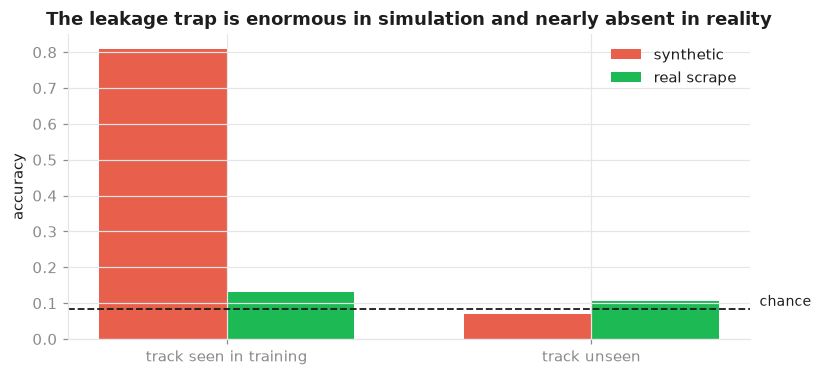

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(2); w = .35
ax.bar(x - w/2, [s_seen, s_unseen], w, label="synthetic", color=viz.WARN)
ax.bar(x + w/2, [r_seen, r_unseen], w, label="real scrape", color=viz.ACCENT)
ax.axhline(S.CHANCE_ACCURACY, color=viz.INK, ls="--", lw=1.2)
ax.text(1.45, S.CHANCE_ACCURACY, " chance", va="bottom", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(["track seen in training", "track unseen"])
ax.set_ylabel("accuracy"); ax.legend()
ax.set_title("The leakage trap is enormous in simulation and nearly absent in reality")
plt.show()

The synthetic gap is ~74 points. The real gap is **under 3**.

The explanation is in how often tracks actually recur, and the generator was wrong
about it in both directions at once.

In [8]:
def overlap_stats(df, label):
    per = df.groupby(S.TRACK_ID).agg(rows=(S.STAR_SIGN, "size"),
                                     signs=(S.STAR_SIGN, "nunique"))
    return {
        "dataset": label,
        "tracks appearing >1×": f"{(per.rows > 1).mean():.1%}",
        "tracks under >1 sign": f"{(per['signs'] > 1).mean():.1%}",
        "rows repeating within own sign":
            f"{df.duplicated([S.TRACK_ID, S.STAR_SIGN], keep=False).mean():.1%}",
    }

pd.DataFrame([overlap_stats(zod_syn, "synthetic (predicted)"),
              overlap_stats(zodiac, "real scrape (actual)")]).set_index("dataset")

,tracks appearing >1×,tracks under >1 sign,rows repeating within own sign
dataset,,,
synthetic (predicted),76.4%,14.5%,90.0%
real scrape (actual),25.3%,23.2%,29.9%


Two things are wrong, and they pull in opposite directions.

**Real playlists repeat tracks far less than modelled** — 25% of tracks appear more
than once, against a predicted 76%. People making an "Aries vibes" playlist mostly do
not copy each other's.

**But when a track does recur, it recurs under a *different* sign** — 23% of tracks
carry more than one sign label, against a predicted 15%. Almost every repeat is a
contradiction rather than a reinforcement.

That inverts the diagnosis. The synthetic data had heavy within-sign repetition, which
is *leakage fuel*. The real data has cross-sign repetition, which is *label noise*.
Both argue for deduplication and grouped splits, but for different reasons — and only
the first one inflates your accuracy.

In [9]:
cluster_cols = [S.PLAYLIST_CLUSTER] if S.PLAYLIST_CLUSTER in zodiac.columns else []
if cluster_cols:
    g = zodiac.groupby(S.STAR_SIGN).agg(playlists=("playlist_id", "nunique"),
                                        clusters=(S.PLAYLIST_CLUSTER, "nunique"))
    g["ESS %"] = (g.clusters / g.playlists * 100).round(1)
    print("Effective sample size after collapsing near-duplicate playlists")
    print("(the generator predicted 63.6%, i.e. evidence overstated 1.57×)\n")
    print(g.to_string())
    print(f"\noverall: {g.clusters.sum()/g.playlists.sum()*100:.1f}%")

Effective sample size after collapsing near-duplicate playlists
(the generator predicted 63.6%, i.e. evidence overstated 1.57×)

             playlists  clusters  ESS %
star_sign                              
Aquarius           134       134  100.0
Aries              138       135   97.8
Cancer              67        67  100.0
Capricorn          119       119  100.0
Gemini             131       125   95.4
Leo                 56        56  100.0
Libra               80        80  100.0
Pisces             151       151  100.0
Sagittarius        111       111  100.0
Scorpio            120       120  100.0
Taurus             106       106  100.0
Virgo              132       132  100.0

overall: 99.3%


Essentially **100%**. The playlist-copy collapse machinery — Jaccard
clustering, cluster-weighted voting, effective sample size — finds almost nothing to
collapse. It was built to solve a problem the real corpus does not have.

Keeping it is still right: it costs nothing, it is the correct guard for a corpus that
*does* have copies, and the only way to know this one doesn't was to measure. But the
honest statement is that **it is not what makes the result weak.**

### The pattern worth naming

This is the fourth assumption the synthetic generator got wrong, and the project kept
finding them only by checking:

| assumption | modelled | real |
|---|---|---|
| feature marginals | median year 2012 | 1992 |
| listener mainstream-ness | uniform across users | varies sharply |
| what defines taste | genre (by construction) | unresolved — the comparison was circular |
| playlist overlap | 76% of tracks repeat | 25% |

Every one of these was written by someone who expected a particular answer, and every
one of them was wrong in the direction of that expectation. The generator remains
useful for testing *mechanisms* — the arithmetic findings in notebook 06 transferred
intact — but any number that depends on its distributional assumptions is provisional
until it is re-measured on real data.

## 4 · So why *is* it weak?

Not leakage, and not a feature-store problem. Run every feature set we have.

In [10]:
rows = []
for label, num, cat, mdl in [
    ("audio features only (41% coverage)", FEATS, (), "rf"),
    ("popularity + year + genre (100%)", [S.POPULARITY, S.YEAR], [S.GENRE], "rf"),
    ("everything combined", FEATS + [S.POPULARITY, S.YEAR], [S.GENRE], "rf"),
    ("audio only, logistic regression", FEATS, (), "lr"),
]:
    src = zodiac if not any(f in FEATS for f in num) else zf
    m, sd, n = grouped_score(src, num, cat, model=mdl)
    rows.append({"features": label, "balanced accuracy": round(m, 4),
                 "± sd": round(sd, 4), "× chance": round(m / S.CHANCE_ACCURACY, 2),
                 "n": n})
res = pd.DataFrame(rows)
res

,features,balanced accuracy,± sd,× chance,n
0,audio features only (41% coverage),0.1067,0.0018,1.28,36116
1,popularity + year + genre (100%),0.1000,0.0039,1.20,87907
2,everything combined,0.1156,0.0024,1.39,36116
3,"audio only, logistic regression",0.1070,0.0020,1.28,36116


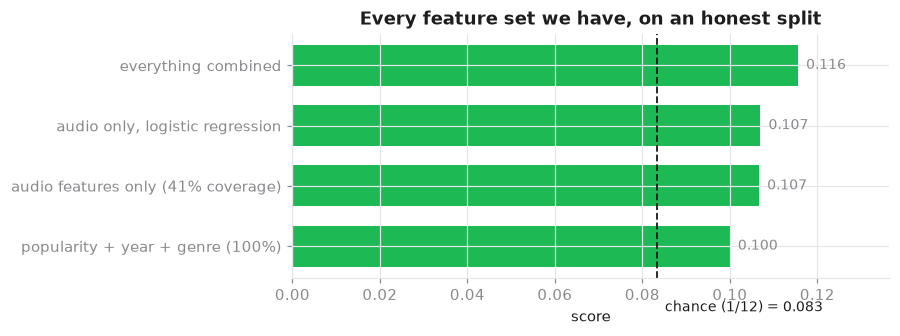

In [11]:
viz.bar_results(res.rename(columns={"balanced accuracy": "score"}),
                "score", "features",
                "Every feature set we have, on an honest split",
                reference=S.CHANCE_ACCURACY, reference_label="chance (1/12)")
plt.show()

Nothing clears 1.4× chance. Throwing more features at it buys a few points
and then stops.

The decisive comparison is in `06_real_data_validation.ipynb`: on the **same catalog,
the same method and the same grouped-split discipline**, predicting a track's *genre*
reaches about **7.3× chance**, while predicting its zodiac sign reaches **1.4×**.

Identical pipeline, identical features, wildly different outcomes. That isolates the
label as the cause. It is not that our features are poor or our models are wrong —
they recover genre perfectly well. It is that the thing we are asking them to predict
is barely encoded in the audio, because a curator's sense of what sounds like an Aries
song is mostly not a property of the song.

## 5 · A baseline subtlety we created ourselves

The class sizes are uneven, and that is **our doing, not astrology's**. The title
filter strips far more playlists from two signs than the rest, because `Cancer` and
`Leo` are also ordinary English words — most "cancer" search hits are about the
disease, most "leo" hits are artists named Leo or León. `Libra` suffers the same way
from a Mexican band called Grupo Libra.

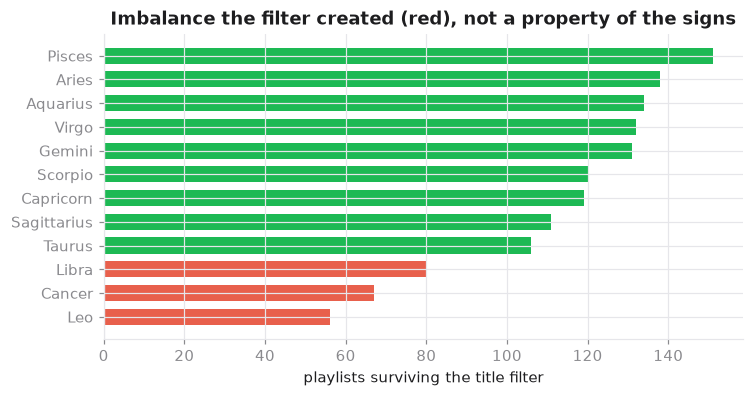

class sizes : max 5,845  min 1,010  ratio 5.79
uniform chance    : 0.0833
majority baseline : 0.1618   <- the real floor for raw accuracy


In [12]:
pl = zodiac.groupby(S.STAR_SIGN).playlist_id.nunique().sort_values()
fig, ax = plt.subplots(figsize=(7.5, 3.6))
colors = [viz.WARN if v < 90 else viz.ACCENT for v in pl]
ax.barh(list(pl.index), pl.to_numpy(), color=colors, height=.68)
ax.set_xlabel("playlists surviving the title filter")
ax.set_title("Imbalance the filter created (red), not a property of the signs")
plt.show()

clean = Z.deduplicate(work, "majority")
vc = clean[S.STAR_SIGN].value_counts()
base = Z.baselines(clean[S.STAR_SIGN])
print(f"class sizes : max {vc.max():,}  min {vc.min():,}  ratio {vc.max()/vc.min():.2f}")
print(f"uniform chance    : {base['uniform']:.4f}")
print(f"majority baseline : {base['majority']:.4f}   <- the real floor for raw accuracy")

With uneven classes, raw accuracy has to be read against the **majority-class
rate (0.162)**, not against 1/12. A model that always guessed Pisces would score 16.2%
and know nothing.

That is why every headline in this notebook is **balanced accuracy** — the macro
average of per-class recall, whose chance level stays at 1/12 however lopsided the
classes get. Quoting raw accuracy here would overstate the result by about a third.

## 6 · What it cost to collect, and a bug worth recording

The scrape plus probes ran roughly **8,000 requests in 90 minutes**. Spotify responded
with a `Retry-After` of **74,655 seconds — 20.7 hours** — which is why the control
stopped at 71 playlists.

The scraper originally obeyed that header literally and without a cap. It spent 15
minutes asleep with no output, two sockets in `CLOSE_WAIT` and 2.8 seconds of CPU,
looking exactly like a deadlock. It now refuses any pause longer than 180 seconds and
raises `RateLimitedTooLong` naming `--resume`, so the wait is visible and the
checkpoint makes resuming free.

Worth stating because it is a planning constraint, not a one-off: **collection is
limited to roughly one sitting per day.**

## 7 · The form of the feature that survives

A 1.3× classifier should not be shipped as a prediction. But "a playful summary of
your taste" never needed a strong classifier — it needed an honest one. Three changes
make the output defensible.

**Average probabilities, not votes.** Hard-classifying each song and counting labels
throws away everything the model was unsure about, and at this accuracy it is unsure
about nearly everything.

**Report lift over the base rate.** A raw "11.9% Capricorn" is mostly a statement about
the class prior. How far a user sits from what the model says about an *average*
listener is the part that is about them.

**Say when there is nothing to say.** The `is_distinctive` flag used to fire at a
hardcoded 1.25× lift, which passed 100% of test users — a badge everyone gets carries
no information. It is now fitted to the reference population's own lift distribution,
so roughly the top quarter earn it.

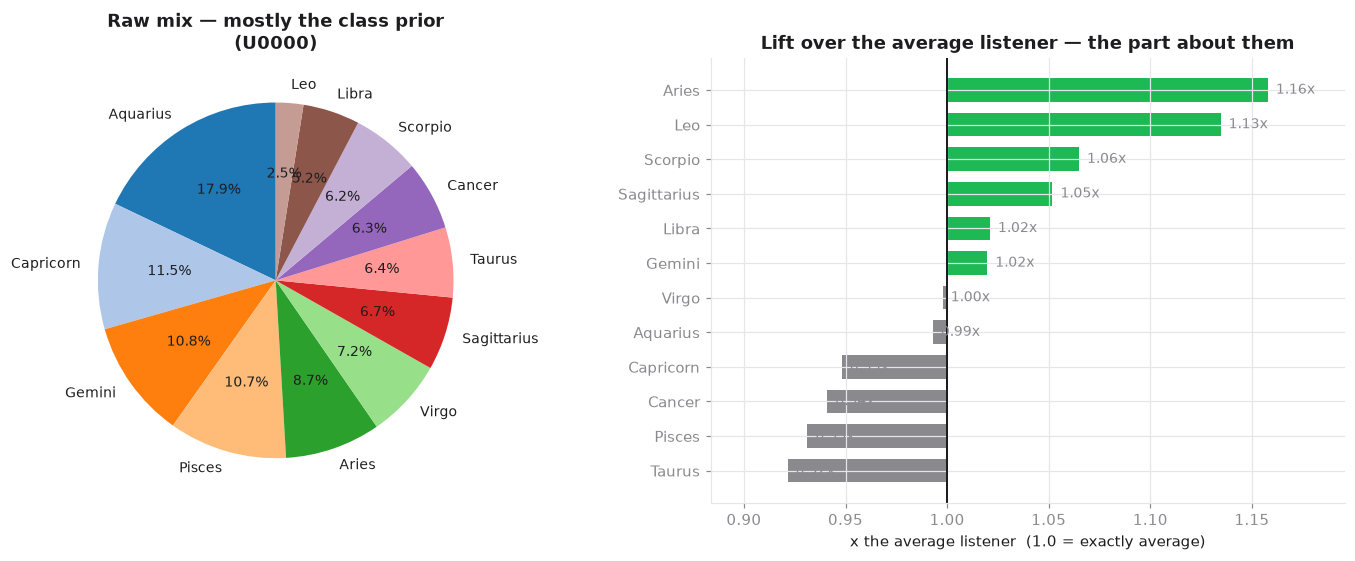

In [13]:
from sklearn.pipeline import make_pipeline as mkpipe

model = mkpipe(StandardScaler(), LogisticRegression(max_iter=2000))
model.fit(clean[FEATS].to_numpy(float), clean[S.STAR_SIGN].to_numpy())

catalog = data.load_catalog(verbose=False)
cat_feats = catalog.dropna(subset=FEATS)
base_rate = Z.taste_mix(model, cat_feats.sample(n=40_000, random_state=0))

listens, _ = data.load_listens(catalog, n_users=120, tracks_per_user=150, verbose=False)
u = listens[S.USER_ID].iloc[0]
mix = Z.taste_mix(model, listens[listens[S.USER_ID] == u])
lift = Z.lift(mix, base_rate)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
viz.taste_mix_pie(mix, f"Raw mix — mostly the class prior\n({u})", ax=axes[0])
viz.lift_chart(lift, "Lift over the average listener — the part about them", ax=axes[1])
plt.tight_layout(); plt.show()

top-sign lift across 120 listeners: median 1.26×, max 1.76×
old hardcoded threshold 1.25× would flag : 52% of users
fitted 75th-percentile threshold 1.35× flags : 25%


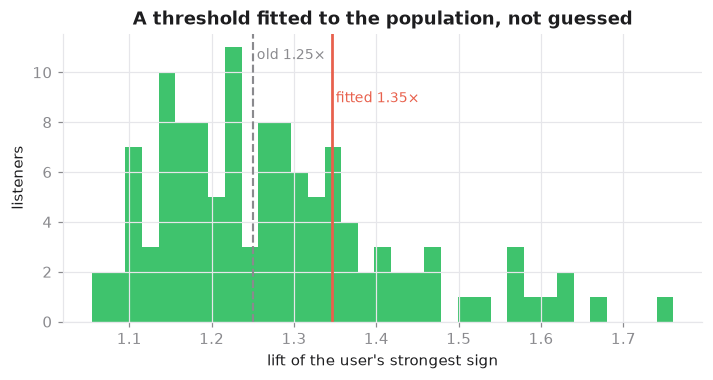

In [14]:
tops = []
for _, g in listens.groupby(S.USER_ID):
    tops.append(float(Z.lift(Z.taste_mix(model, g), base_rate).iloc[0]))
tops = np.array(tops)
fitted = float(np.quantile(tops, 0.75))

print(f"top-sign lift across {len(tops)} listeners: median {np.median(tops):.2f}×, "
      f"max {tops.max():.2f}×")
print(f"old hardcoded threshold 1.25× would flag : {(tops >= 1.25).mean():.0%} of users")
print(f"fitted 75th-percentile threshold {fitted:.2f}× flags : {(tops >= fitted).mean():.0%}")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.hist(tops, bins=35, color=viz.ACCENT, alpha=.85)
ax.axvline(1.25, color=viz.MUTED, ls="--", lw=1.4)
ax.text(1.25, ax.get_ylim()[1]*.95, " old 1.25×", color=viz.MUTED, fontsize=9, va="top")
ax.axvline(fitted, color=viz.WARN, lw=1.8)
ax.text(fitted, ax.get_ylim()[1]*.80, f" fitted {fitted:.2f}×", color=viz.WARN, fontsize=9, va="top")
ax.set_xlabel("lift of the user's strongest sign"); ax.set_ylabel("listeners")
ax.set_title("A threshold fitted to the population, not guessed")
plt.show()

**The alternative that needs no labels at all** is in
`07_archetypes.ipynb`: cluster the catalog into twelve audio archetypes and attach
zodiac names through a documented mapping. The user sees the same pie chart, but there
is no label to be noisy, no curator to disagree with, and no accuracy claim to defend.
It is honest by construction rather than by careful framing.

## Verdict

Against thresholds written into `scripts/decision_gate.py` **before** the scrape was
run:

| gate band | criterion | this result |
|---|---|---|
| dead | balanced accuracy ≤ 0.12 | **0.100 – 0.116** ← lands here |
| weak but real | 0.12 – 0.20 | |
| genuinely interesting | > 0.20 | |

| claim | status |
|---|---|
| Zodiac sign is predictable from audio | **barely** — 1.2–1.4× chance, every feature set |
| The signal is a pipeline artefact | **no** — control with random labels sits at 0.94× chance |
| The weak result is caused by leakage | **no** — the real seen/unseen gap is under 3 points |
| Real playlists copy each other heavily | **no** — ESS ~100%, 25% of tracks ever repeat |
| The cause is the label, not the features | **yes** — identical pipeline gets 7.3× chance on genre |
| Worth shipping as a prediction | **no** |
| Worth shipping as a taste summary | **yes**, with lift framing and a fitted distinctiveness bar |

### What would change the answer

Nothing about the modelling. The ceiling is set by what the labels encode, so better
algorithms cannot move it, and we have now confirmed that on real data rather than
inferring it.

Three things could:

1. **Finish the control** (71 of 480 playlists). It is the only number here resting on
   a thin sample, and everything else leans on it.
2. **Restrict to high-confidence labels** — tracks several independent playlists agree
   on. Smaller, cleaner, and it would separate "the labels are noisy" from "the labels
   are empty", which this notebook cannot currently distinguish.
3. **Ask people their actual sign** (`SURVEY.md`). That tests the hypothesis the
   product implies, rather than what playlist curators believe about it, and it needs
   no API access.

→ `06_real_data_validation.ipynb` for what else survived real data, and
`07_archetypes.ipynb` for the version that ships.